In [1]:
import torch
import torch.nn as nn
import numpy as np
import trimesh
import matplotlib.pyplot as plt
import pandas as pd
import os
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import random

In [2]:
def prepareDevice():
    device = torch.device("cpu")
    random.seed(42)
    os.environ['PYTHONHASHSEED'] = '42'
    np.random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed(42)
        torch.cuda.manual_seed_all(42)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print("Using CUDA")
    else:
        print("Using CPU")

    return device

device = prepareDevice()

Using CUDA


In [3]:
class Transform3DDataset(Dataset):
    def __init__(self, source_path, target_path, num_points=2048, augment=False, epoch_size=100):
        self.num_points = num_points
        self.augment = augment
        self.epoch_size = epoch_size
        
        self.source_mesh = trimesh.load(source_path)
        self.target_mesh = trimesh.load(target_path)
        
        self.source_vertices = self._normalize(self.source_mesh.vertices)
        self.target_vertices = self._normalize(self.target_mesh.vertices)
        
        self.source_mesh.vertices = self.source_vertices
        self.target_mesh.vertices = self.target_vertices

    def _normalize(self, vertices):
        centroid = np.mean(vertices, axis=0)
        vertices = vertices - centroid
        max_distance = np.max(np.sqrt(np.sum(vertices**2, axis=1)))
        vertices = vertices / max_distance
        return vertices

    def _augment(self, points):
        angles = np.random.uniform(-np.pi, np.pi, 3)
        
        Rx = np.array([[1, 0, 0],
                       [0, np.cos(angles[0]), -np.sin(angles[0])],
                       [0, np.sin(angles[0]), np.cos(angles[0])]])
                       
        Ry = np.array([[np.cos(angles[1]), 0, np.sin(angles[1])],
                       [0, 1, 0],
                       [-np.sin(angles[1]), 0, np.cos(angles[1])]])
                       
        Rz = np.array([[np.cos(angles[2]), -np.sin(angles[2]), 0],
                       [np.sin(angles[2]), np.cos(angles[2]), 0],
                       [0, 0, 1]])
                       
        R = Rz @ Ry @ Rx
        
        points = points @ R.T
        
        scale = np.random.uniform(0.8, 1.2)
        points *= scale
        
        return points

    def __len__(self):
        return self.epoch_size

    def __getitem__(self, idx):
        source_points, _ = trimesh.sample.sample_surface(self.source_mesh, self.num_points)
        target_points, _ = trimesh.sample.sample_surface(self.target_mesh, self.num_points)
        
        if self.augment:
            source_points = self._augment(source_points)
            
        return {
            'source': torch.tensor(source_points, dtype=torch.float32),
            'target': torch.tensor(target_points, dtype=torch.float32)
        }

In [4]:
DIR_MODELS = "modele"
path_teapot = os.path.join(DIR_MODELS, "teapot.obj")
path_bunny = os.path.join(DIR_MODELS, "bunny.obj")
path_dragon = os.path.join(DIR_MODELS, "dragon_small.obj")
path_armadillo = os.path.join(DIR_MODELS, "armadillo_small.obj")
path_asian_dragon = os.path.join(DIR_MODELS, "asian_dragon_really_small.obj") # Do testów na koniec

BATCH_SIZE = 4
NUM_POINTS = 2048 

dataset_bunny = Transform3DDataset(path_bunny, path_teapot, num_points=NUM_POINTS, augment=False)
dataset_dragon = Transform3DDataset(path_dragon, path_teapot, num_points=NUM_POINTS, augment=False)
dataset_armadillo = Transform3DDataset(path_armadillo, path_teapot, num_points=NUM_POINTS, augment=False)
dataset_asian_dragon = Transform3DDataset(path_asian_dragon, path_teapot, num_points=NUM_POINTS, augment=False)

loader_bunny = DataLoader(dataset_bunny, batch_size=BATCH_SIZE, shuffle=True)
loader_dragon = DataLoader(dataset_dragon, batch_size=BATCH_SIZE, shuffle=True)
loader_armadillo = DataLoader(dataset_armadillo, batch_size=BATCH_SIZE, shuffle=True)
loader_asian_dragon = DataLoader(dataset_asian_dragon, batch_size=BATCH_SIZE, shuffle=True)

batch = next(iter(loader_bunny))
print("Shape of source data (Bunny):", batch['source'].shape)
print("Shape of target data (Teapot):", batch['target'].shape)

Shape of source data (Bunny): torch.Size([4, 2048, 3])
Shape of target data (Teapot): torch.Size([4, 2048, 3])


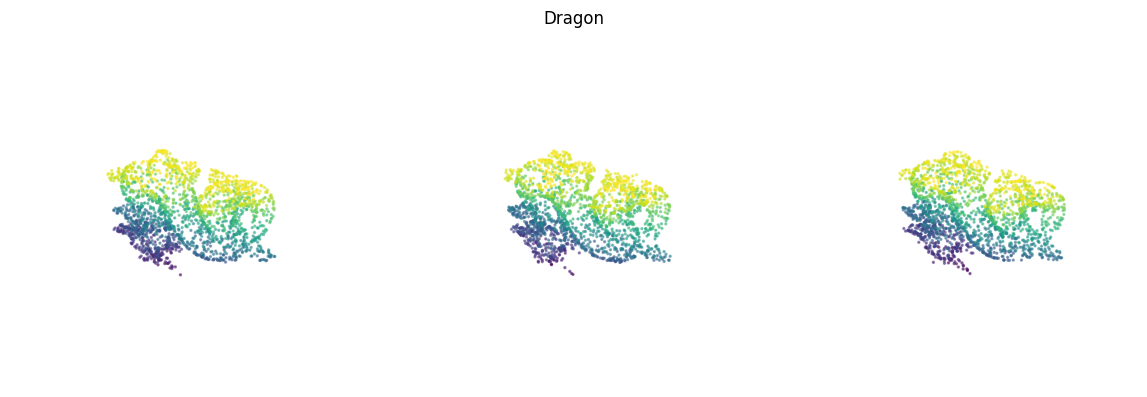

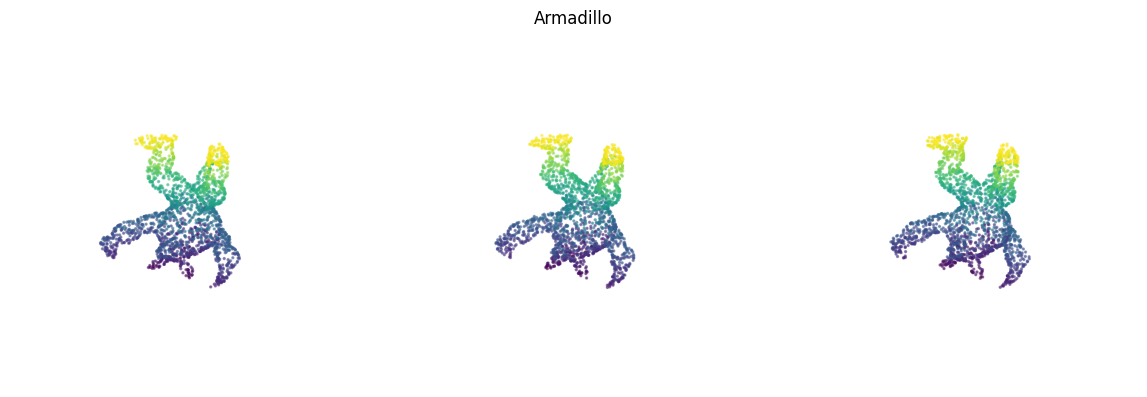

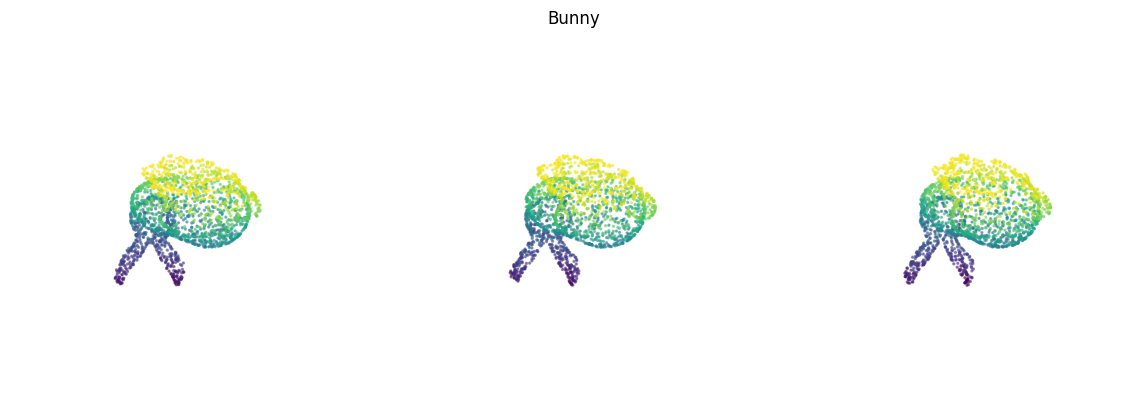

In [5]:
def visualize_dataset_sample(dataset, title_source="Input Object"):   
    fig = plt.figure(figsize=(12, 4))
    n = 3
    for idx in range(n):
        try:
            sample = dataset[idx]
            source_points = sample['source'].numpy()
            ax = fig.add_subplot(1, n, idx+1, projection='3d')
            ax.scatter(source_points[:, 0], source_points[:, 1], source_points[:, 2], s=2, c=source_points[:, 2], cmap='viridis', alpha=0.5)
            ax.set_xlim([-1, 1])
            ax.set_ylim([-1, 1])
            ax.set_zlim([-1, 1])
            ax.axis('off')
        except IndexError:
            print(f"Cannot retrieve sample with index {idx} from the dataset.")
    plt.suptitle(title_source)
    plt.tight_layout()
    plt.show()

visualize_dataset_sample(dataset_dragon, title_source="Dragon")
visualize_dataset_sample(dataset_armadillo, title_source="Armadillo")
visualize_dataset_sample(dataset_bunny, title_source="Bunny")

# Model

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, num_frequencies=6):
        super().__init__()
        self.num_frequencies = num_frequencies

    def forward(self, x):
        encodings = [x] 
        
        for i in range(self.num_frequencies):
            for fn in [torch.sin, torch.cos]:
                encodings.append(fn((2.0 ** i) * np.pi * x))
                
        return torch.cat(encodings, dim=-1)

class VectorFieldMLP(nn.Module):
    def __init__(self, num_frequencies=6, hidden_dim=256):
        super().__init__()
        self.pe = PositionalEncoding(num_frequencies=num_frequencies)
        
        in_dim = 3 + 3 * 2 * num_frequencies
        
        # Deep MLP
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, 3)
        )

    def forward(self, x):
        x_encoded = self.pe(x)
        displacement = self.net(x_encoded)
        return displacement

In [7]:
class VectorFieldMLPPro(nn.Module):
    def __init__(self, input_dim=3, num_freqs=10, hidden_dim=256, skip_layer=4):
        super().__init__()
        self.pe = PositionalEncoding(num_frequencies=num_freqs)
        
        in_dim = input_dim + input_dim * 2 * num_freqs
        
        self.block1 = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100)
        )
        
        self.block2 = nn.Sequential(
            nn.Linear(hidden_dim + in_dim, hidden_dim), 
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Softplus(beta=100),
            nn.Linear(hidden_dim, 3) 
        )
        
        nn.init.normal_(self.block2[-1].weight, mean=0.0, std=1e-5)
        nn.init.constant_(self.block2[-1].bias, 0.0)

    def forward(self, x):
        x_encoded = self.pe(x)
        h = self.block1(x_encoded)
        h = torch.cat([h, x_encoded], dim=-1)
        displacement = self.block2(h)
        
        return displacement

In [8]:
# test
dummy_points = torch.randn(1, 2048, 3)
dummy_model = VectorFieldMLP(num_frequencies=6, hidden_dim=256)
vector_field = dummy_model(dummy_points)
transformed_points = dummy_points + vector_field
dummy_model_pro = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4)
vector_field_pro = dummy_model_pro(dummy_points)
transformed_points_pro = dummy_points + vector_field_pro
print("Input shape (Basic):", dummy_points.shape)
print("Output shape (Basic):", vector_field.shape)
print("Transformed shape (Basic):", transformed_points.shape)
print("Input shape (Pro):", dummy_points.shape)
print("Output shape (Pro):", vector_field_pro.shape)
print("Transformed shape (Pro):", transformed_points_pro.shape)

Input shape (Basic): torch.Size([1, 2048, 3])
Output shape (Basic): torch.Size([1, 2048, 3])
Transformed shape (Basic): torch.Size([1, 2048, 3])
Input shape (Pro): torch.Size([1, 2048, 3])
Output shape (Pro): torch.Size([1, 2048, 3])
Transformed shape (Pro): torch.Size([1, 2048, 3])


Trening

In [9]:
def chamfer_distance(p1, p2):
    dists_sq = torch.cdist(p1, p2) ** 2
    min_dist_p1_to_p2, _ = torch.min(dists_sq, dim=2) 
    min_dist_p2_to_p1, _ = torch.min(dists_sq, dim=1) 
    loss = torch.mean(min_dist_p1_to_p2) + torch.mean(min_dist_p2_to_p1)
    
    return loss

In [10]:
def train_model(model, dataloader, optimizer, num_epochs=100):
    model.to(device)

    for epoch in tqdm(range(num_epochs), desc="Training"):
        model.train()
        total_loss = 0.0
        total_cd = 0.0
        total_reg = 0.0
        
        for batch in (dataloader):
            source_points = batch['source'].to(device)
            target_points = batch['target'].to(device)

            optimizer.zero_grad()
            predicted_displacement = model(source_points)
            transformed_points = source_points + predicted_displacement

            loss_cd = chamfer_distance(transformed_points, target_points)
            loss_reg = torch.mean(predicted_displacement**2)
            loss = 1000.0 * loss_cd + 1.0 * loss_reg
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            total_cd += loss_cd.item()
            total_reg += loss_reg.item()
        
        avg_loss = total_loss / len(dataloader)
        avg_cd = total_cd / len(dataloader)
        avg_reg = total_reg / len(dataloader)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1} | Total Loss: {avg_loss:.4f} | Chamfer: {avg_cd:.6f} | Reg: {avg_reg:.6f}")

In [11]:
def visualize_morphing(model, dataset, device, title="Transformation"):
    model.eval() 
    sample = dataset[0]
    source_points = sample['source'].unsqueeze(0).to(device)
    
    with torch.no_grad():
        final_displacement = model(source_points)
    
    source_points_np = source_points[0].cpu().numpy()
    displacement_np = final_displacement[0].cpu().numpy()

    steps = [0.0, 0.33, 0.66, 1.0] 
    
    fig = plt.figure(figsize=(15, 5))

    for i, t in enumerate(steps):
        ax = fig.add_subplot(1, 4, i+1, projection='3d')

        current_points = source_points_np + (displacement_np * t)

        ax.scatter(current_points[:, 0], current_points[:, 1], current_points[:, 2], 
                   s=2, c=current_points[:, 2], cmap='viridis', alpha=0.8)
        
        if t == 0.0:
            step_title = f"{title}\nStart (t=0)"
        elif t == 1.0:
            step_title = f"{title}\nEnd (t=1)"
        else:
            step_title = f"{title}\nIntermediate step (t={t:.2f})"
            
        ax.set_title(step_title)
        
        ax.set_xlim([-1, 1])
        ax.set_ylim([-1, 1])
        ax.set_zlim([-1, 1])
        ax.axis('off')

    plt.tight_layout()
    plt.show()

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 17.8946 | Chamfer: 0.017878 | Reg: 0.016248
Epoch 10 | Total Loss: 1.5675 | Chamfer: 0.001542 | Reg: 0.025792
Epoch 20 | Total Loss: 1.4768 | Chamfer: 0.001449 | Reg: 0.027864
Epoch 30 | Total Loss: 1.4567 | Chamfer: 0.001429 | Reg: 0.027914
Epoch 40 | Total Loss: 1.4252 | Chamfer: 0.001398 | Reg: 0.027696
Epoch 50 | Total Loss: 1.4094 | Chamfer: 0.001381 | Reg: 0.028319
Epoch 60 | Total Loss: 1.4076 | Chamfer: 0.001380 | Reg: 0.027966
Epoch 70 | Total Loss: 1.4033 | Chamfer: 0.001376 | Reg: 0.027653
Epoch 80 | Total Loss: 1.3990 | Chamfer: 0.001372 | Reg: 0.027121
Epoch 90 | Total Loss: 1.3957 | Chamfer: 0.001367 | Reg: 0.028327
Epoch 100 | Total Loss: 1.3901 | Chamfer: 0.001363 | Reg: 0.027562
Epoch 110 | Total Loss: 1.3903 | Chamfer: 0.001363 | Reg: 0.027540
Epoch 120 | Total Loss: 1.3863 | Chamfer: 0.001359 | Reg: 0.027582
Epoch 130 | Total Loss: 1.3911 | Chamfer: 0.001364 | Reg: 0.027526
Epoch 140 | Total Loss: 1.3851 | Chamfer: 0.001357 | Reg: 0.027765
Epoch

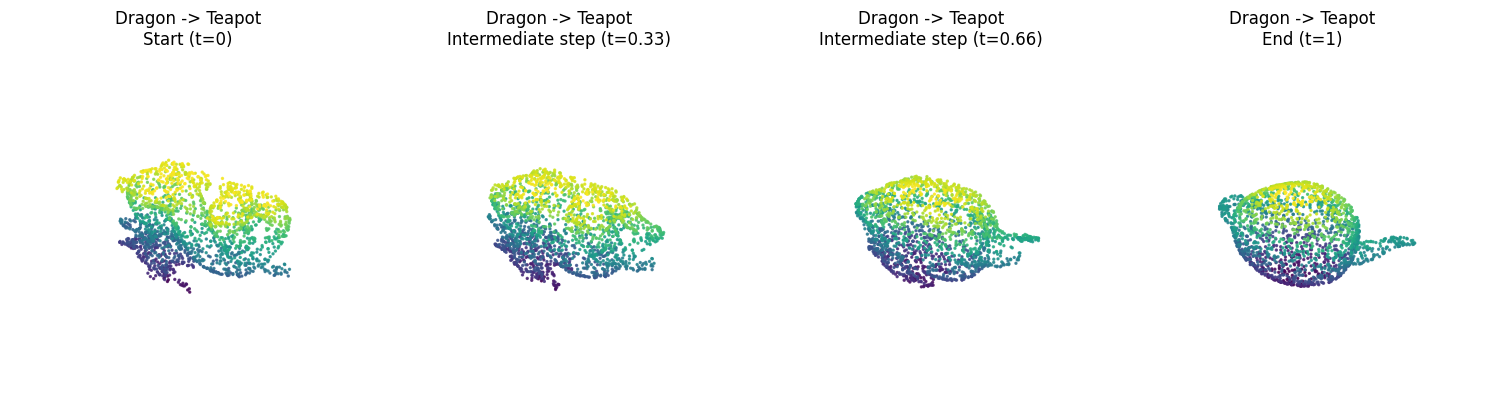

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 10.9876 | Chamfer: 0.010974 | Reg: 0.013442
Epoch 10 | Total Loss: 1.5009 | Chamfer: 0.001481 | Reg: 0.019489
Epoch 20 | Total Loss: 1.4190 | Chamfer: 0.001399 | Reg: 0.020265
Epoch 30 | Total Loss: 1.4006 | Chamfer: 0.001380 | Reg: 0.020380
Epoch 40 | Total Loss: 1.3850 | Chamfer: 0.001365 | Reg: 0.020070
Epoch 50 | Total Loss: 1.3766 | Chamfer: 0.001357 | Reg: 0.019955
Epoch 60 | Total Loss: 1.3760 | Chamfer: 0.001356 | Reg: 0.020258
Epoch 70 | Total Loss: 1.3690 | Chamfer: 0.001349 | Reg: 0.019540
Epoch 80 | Total Loss: 1.3692 | Chamfer: 0.001350 | Reg: 0.019382
Epoch 90 | Total Loss: 1.3654 | Chamfer: 0.001347 | Reg: 0.018758
Epoch 100 | Total Loss: 1.3721 | Chamfer: 0.001354 | Reg: 0.018431
Epoch 110 | Total Loss: 1.3551 | Chamfer: 0.001336 | Reg: 0.018980
Epoch 120 | Total Loss: 1.3576 | Chamfer: 0.001339 | Reg: 0.018424
Epoch 130 | Total Loss: 1.3611 | Chamfer: 0.001342 | Reg: 0.018899
Epoch 140 | Total Loss: 1.3622 | Chamfer: 0.001343 | Reg: 0.018795
Epoch

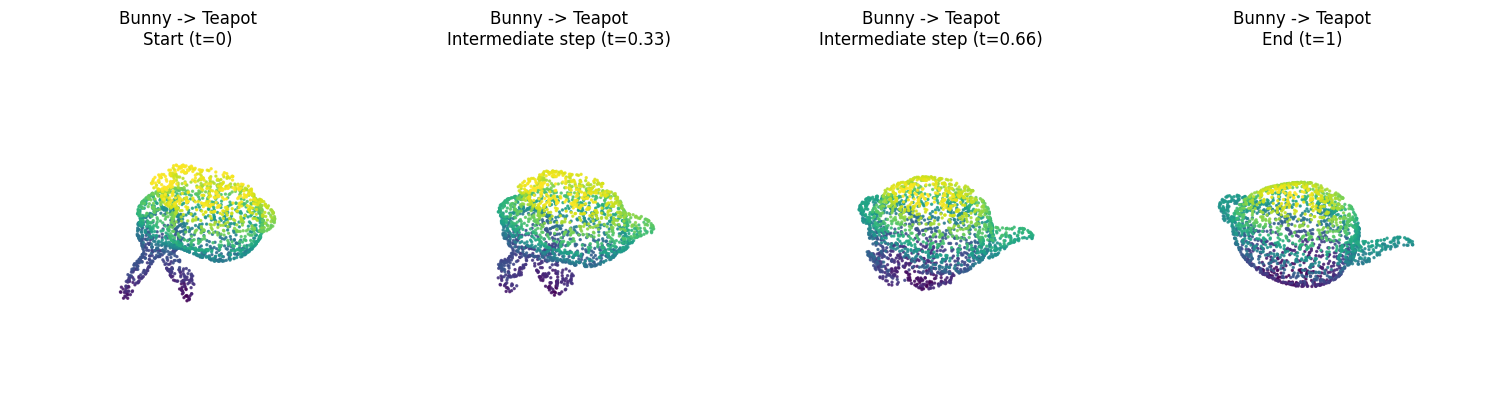

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 27.7048 | Chamfer: 0.027677 | Reg: 0.028122
Epoch 10 | Total Loss: 1.7078 | Chamfer: 0.001661 | Reg: 0.046316
Epoch 20 | Total Loss: 1.5430 | Chamfer: 0.001496 | Reg: 0.046538
Epoch 30 | Total Loss: 1.4732 | Chamfer: 0.001429 | Reg: 0.044613
Epoch 40 | Total Loss: 1.4572 | Chamfer: 0.001411 | Reg: 0.045701
Epoch 50 | Total Loss: 1.4480 | Chamfer: 0.001403 | Reg: 0.045062
Epoch 60 | Total Loss: 1.4477 | Chamfer: 0.001402 | Reg: 0.045648
Epoch 70 | Total Loss: 1.4323 | Chamfer: 0.001387 | Reg: 0.045052
Epoch 80 | Total Loss: 1.4185 | Chamfer: 0.001373 | Reg: 0.045471
Epoch 90 | Total Loss: 1.4178 | Chamfer: 0.001373 | Reg: 0.044904
Epoch 100 | Total Loss: 1.4342 | Chamfer: 0.001390 | Reg: 0.043985
Epoch 110 | Total Loss: 1.4106 | Chamfer: 0.001367 | Reg: 0.043621
Epoch 120 | Total Loss: 1.4248 | Chamfer: 0.001381 | Reg: 0.043952
Epoch 130 | Total Loss: 1.4136 | Chamfer: 0.001370 | Reg: 0.043943
Epoch 140 | Total Loss: 1.4054 | Chamfer: 0.001361 | Reg: 0.044338
Epoch

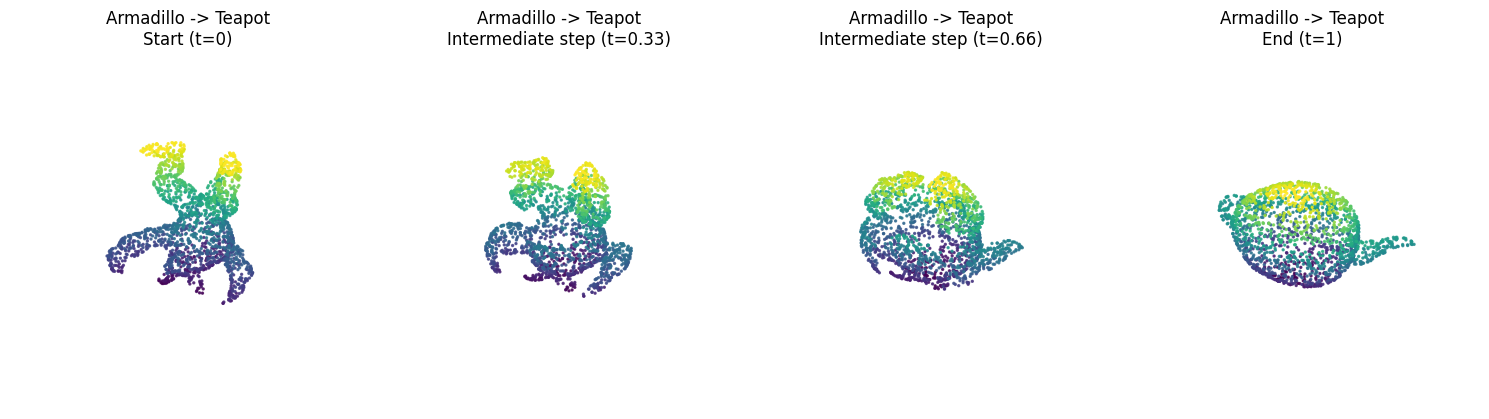

In [12]:
model_dragon_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256)
model_bunny_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256)
model_armadillo_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256)

for model, loader, name in zip([model_dragon_basic, model_bunny_basic, model_armadillo_basic], [loader_dragon, loader_bunny, loader_armadillo], ["Dragon -> Teapot", "Bunny -> Teapot", "Armadillo -> Teapot"]):
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    train_model(model, loader, optimizer, num_epochs=500)
    model.eval()
    visualize_morphing(model, loader.dataset, device, title=name)

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 40.7156 | Chamfer: 0.040708 | Reg: 0.007541
Epoch 10 | Total Loss: 2.0099 | Chamfer: 0.001984 | Reg: 0.026321
Epoch 20 | Total Loss: 1.6419 | Chamfer: 0.001614 | Reg: 0.027845
Epoch 30 | Total Loss: 1.5444 | Chamfer: 0.001517 | Reg: 0.027842
Epoch 40 | Total Loss: 1.4933 | Chamfer: 0.001466 | Reg: 0.027447
Epoch 50 | Total Loss: 1.4650 | Chamfer: 0.001437 | Reg: 0.027734
Epoch 60 | Total Loss: 1.4498 | Chamfer: 0.001422 | Reg: 0.027370
Epoch 70 | Total Loss: 1.4340 | Chamfer: 0.001406 | Reg: 0.027974
Epoch 80 | Total Loss: 1.4201 | Chamfer: 0.001393 | Reg: 0.027207
Epoch 90 | Total Loss: 1.4186 | Chamfer: 0.001391 | Reg: 0.027661
Epoch 100 | Total Loss: 1.4169 | Chamfer: 0.001389 | Reg: 0.027593
Epoch 110 | Total Loss: 1.4083 | Chamfer: 0.001381 | Reg: 0.027166
Epoch 120 | Total Loss: 1.4068 | Chamfer: 0.001380 | Reg: 0.026675
Epoch 130 | Total Loss: 1.4033 | Chamfer: 0.001376 | Reg: 0.027293
Epoch 140 | Total Loss: 1.3919 | Chamfer: 0.001365 | Reg: 0.027162
Epoch

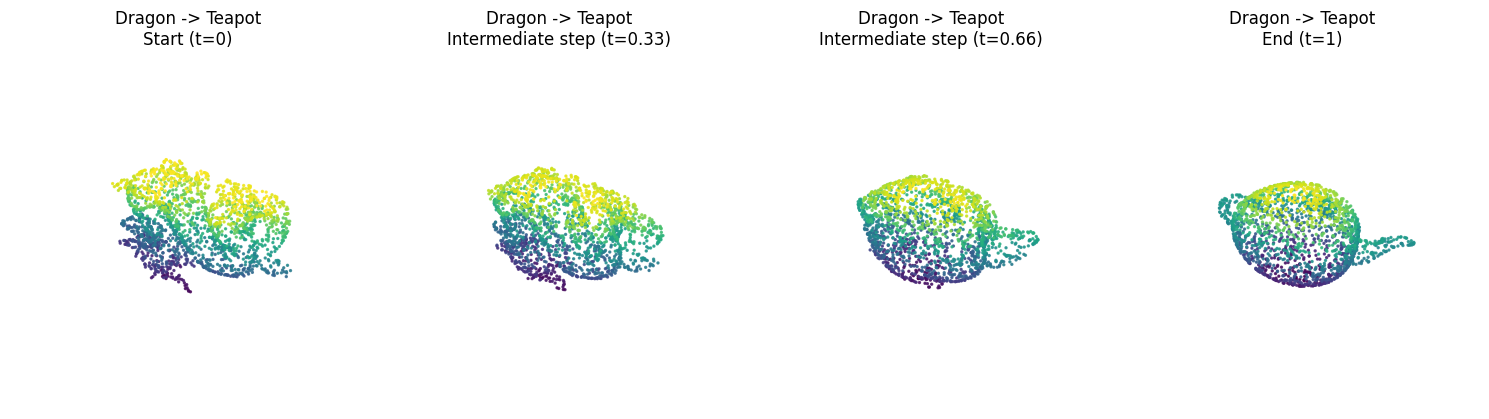

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 24.6077 | Chamfer: 0.024600 | Reg: 0.007876
Epoch 10 | Total Loss: 1.7236 | Chamfer: 0.001706 | Reg: 0.017515
Epoch 20 | Total Loss: 1.5456 | Chamfer: 0.001528 | Reg: 0.017693
Epoch 30 | Total Loss: 1.4784 | Chamfer: 0.001460 | Reg: 0.018725
Epoch 40 | Total Loss: 1.4494 | Chamfer: 0.001431 | Reg: 0.018735
Epoch 50 | Total Loss: 1.4221 | Chamfer: 0.001404 | Reg: 0.018135
Epoch 60 | Total Loss: 1.4091 | Chamfer: 0.001391 | Reg: 0.018430
Epoch 70 | Total Loss: 1.4072 | Chamfer: 0.001389 | Reg: 0.018382
Epoch 80 | Total Loss: 1.3878 | Chamfer: 0.001369 | Reg: 0.018270
Epoch 90 | Total Loss: 1.3863 | Chamfer: 0.001368 | Reg: 0.018280
Epoch 100 | Total Loss: 1.3820 | Chamfer: 0.001363 | Reg: 0.018794
Epoch 110 | Total Loss: 1.3764 | Chamfer: 0.001358 | Reg: 0.018654
Epoch 120 | Total Loss: 1.3762 | Chamfer: 0.001358 | Reg: 0.018427
Epoch 130 | Total Loss: 1.3704 | Chamfer: 0.001352 | Reg: 0.018070
Epoch 140 | Total Loss: 1.3679 | Chamfer: 0.001350 | Reg: 0.017929
Epoch

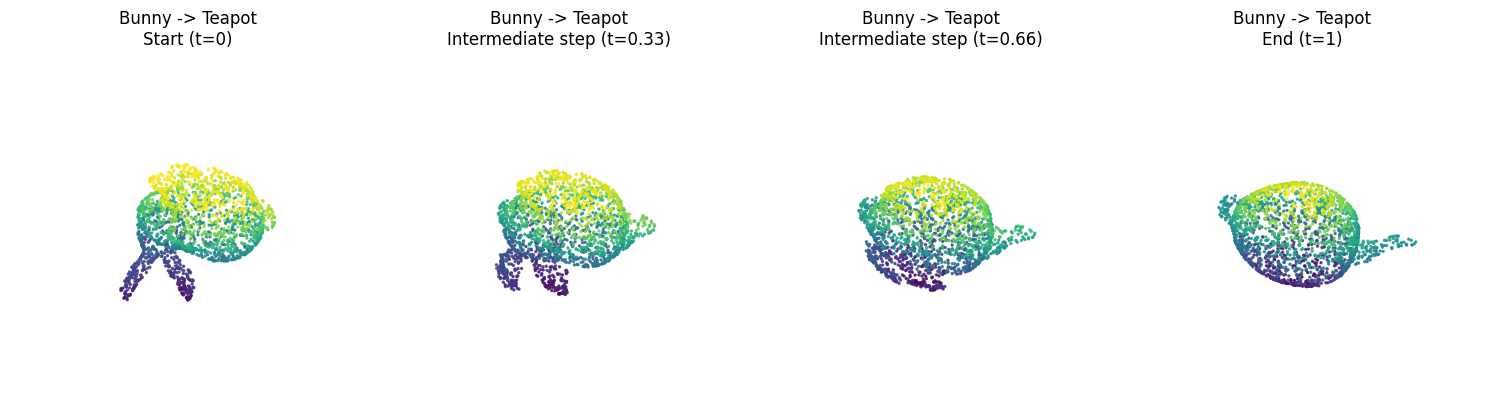

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1 | Total Loss: 57.4144 | Chamfer: 0.057401 | Reg: 0.013021
Epoch 10 | Total Loss: 2.1826 | Chamfer: 0.002120 | Reg: 0.062391
Epoch 20 | Total Loss: 1.7777 | Chamfer: 0.001718 | Reg: 0.059661
Epoch 30 | Total Loss: 1.6188 | Chamfer: 0.001560 | Reg: 0.058930
Epoch 40 | Total Loss: 1.5517 | Chamfer: 0.001492 | Reg: 0.059571
Epoch 50 | Total Loss: 1.5235 | Chamfer: 0.001466 | Reg: 0.057977
Epoch 60 | Total Loss: 1.4968 | Chamfer: 0.001439 | Reg: 0.057681
Epoch 70 | Total Loss: 1.4633 | Chamfer: 0.001407 | Reg: 0.056224
Epoch 80 | Total Loss: 1.4573 | Chamfer: 0.001402 | Reg: 0.055403
Epoch 90 | Total Loss: 1.4518 | Chamfer: 0.001397 | Reg: 0.055059
Epoch 100 | Total Loss: 1.4484 | Chamfer: 0.001394 | Reg: 0.054488
Epoch 110 | Total Loss: 1.4437 | Chamfer: 0.001390 | Reg: 0.054059
Epoch 120 | Total Loss: 1.4303 | Chamfer: 0.001377 | Reg: 0.053290
Epoch 130 | Total Loss: 1.4259 | Chamfer: 0.001373 | Reg: 0.053161
Epoch 140 | Total Loss: 1.4215 | Chamfer: 0.001368 | Reg: 0.053772
Epoch

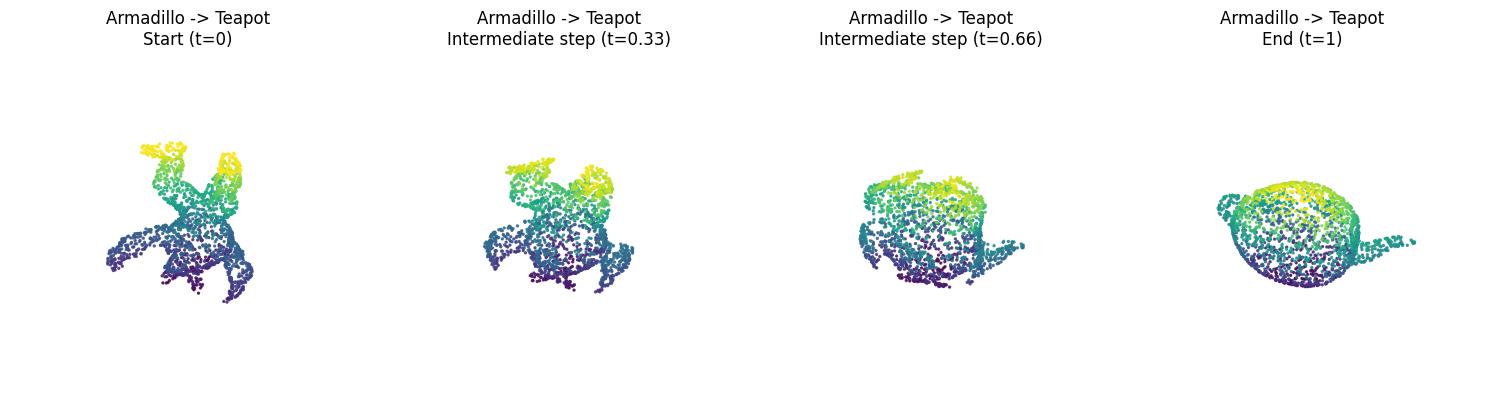

In [13]:
model_dragon = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10)
model_bunny = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10)
model_armadillo = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10)

for model, loader, name in zip([model_dragon, model_bunny, model_armadillo], [loader_dragon, loader_bunny, loader_armadillo], ["Dragon -> Teapot", "Bunny -> Teapot", "Armadillo -> Teapot"]):
    optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
    train_model(model, loader, optimizer, num_epochs=500)
    model.eval()
    visualize_morphing(model, loader.dataset, device, title=name)

In [14]:
torch.save(model_dragon_basic.state_dict(), 'model_dragon_basic_cp.pth')
torch.save(model_bunny_basic.state_dict(), 'model_bunny_basic_cp.pth')
torch.save(model_armadillo_basic.state_dict(), 'model_armadillo_basic_cp.pth')
torch.save(model_dragon.state_dict(), 'model_dragon_pro_cp.pth')
torch.save(model_bunny.state_dict(), 'model_bunny_pro_cp.pth')
torch.save(model_armadillo.state_dict(), 'model_armadillo_pro_cp.pth')

In [15]:
def save_reconstructed_mesh(model, source_mesh_path, output_path, device):
    model.eval() 
    source_mesh = trimesh.load(source_mesh_path)

    vertices = source_mesh.vertices
    centroid = vertices.mean(axis=0)
    vertices = vertices - centroid
    max_distance = np.max(np.sqrt(np.sum(vertices**2, axis=1)))
    vertices = vertices / max_distance

    vertices_tensor = torch.tensor(vertices, dtype=torch.float32).unsqueeze(0).to(device)
    
    with torch.no_grad():
        displacement = model(vertices_tensor)
        
    deformed_vertices = vertices_tensor + displacement
    deformed_vertices_np = deformed_vertices.squeeze(0).cpu().numpy()
    
    reconstructed_mesh = trimesh.Trimesh(vertices=deformed_vertices_np, 
                                         faces=source_mesh.faces)
    
    reconstructed_mesh.export(output_path)
    print(f"Saved reconstructed mesh to: {output_path}")

In [16]:
save_reconstructed_mesh(model_dragon_basic, "modele/dragon_small.obj", "output/reconstructed_dragon_basic_cp.obj", device)
save_reconstructed_mesh(model_bunny_basic, "modele/bunny.obj", "output/reconstructed_bunny_basic_cp.obj", device)
save_reconstructed_mesh(model_armadillo_basic, "modele/armadillo_small.obj", "output/reconstructed_armadillo_basic_cp.obj", device)
save_reconstructed_mesh(model_dragon, "modele/dragon_small.obj", "output/reconstructed_dragon_pro_cp.obj", device)
save_reconstructed_mesh(model_bunny, "modele/bunny.obj", "output/reconstructed_bunny_pro_cp.obj", device)
save_reconstructed_mesh(model_armadillo, "modele/armadillo_small.obj", "output/reconstructed_armadillo_pro_cp.obj", device)

Saved reconstructed mesh to: output/reconstructed_dragon_basic_cp.obj
Saved reconstructed mesh to: output/reconstructed_bunny_basic_cp.obj
Saved reconstructed mesh to: output/reconstructed_armadillo_basic_cp.obj
Saved reconstructed mesh to: output/reconstructed_dragon_pro_cp.obj
Saved reconstructed mesh to: output/reconstructed_bunny_pro_cp.obj
Saved reconstructed mesh to: output/reconstructed_armadillo_pro_cp.obj


In [17]:
model_dragon_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256).to(device)
model_bunny_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256).to(device)
model_armadillo_basic = VectorFieldMLP(num_frequencies=3, hidden_dim=256).to(device)
model_dragon = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4).to(device)
model_bunny = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4).to(device)
model_armadillo = VectorFieldMLPPro(input_dim=3, hidden_dim=256, num_freqs=10, skip_layer=4).to(device)
model_dragon_basic.load_state_dict(torch.load('model_dragon_basic_cp.pth', map_location=device))
model_bunny_basic.load_state_dict(torch.load('model_bunny_basic_cp.pth', map_location=device))
model_armadillo_basic.load_state_dict(torch.load('model_armadillo_basic_cp.pth', map_location=device))
model_dragon.load_state_dict(torch.load('model_dragon_pro_cp.pth', map_location=device))
model_bunny.load_state_dict(torch.load('model_bunny_pro_cp.pth', map_location=device))
model_armadillo.load_state_dict(torch.load('model_armadillo_pro_cp.pth', map_location=device))

<All keys matched successfully>

# Asian Dragon

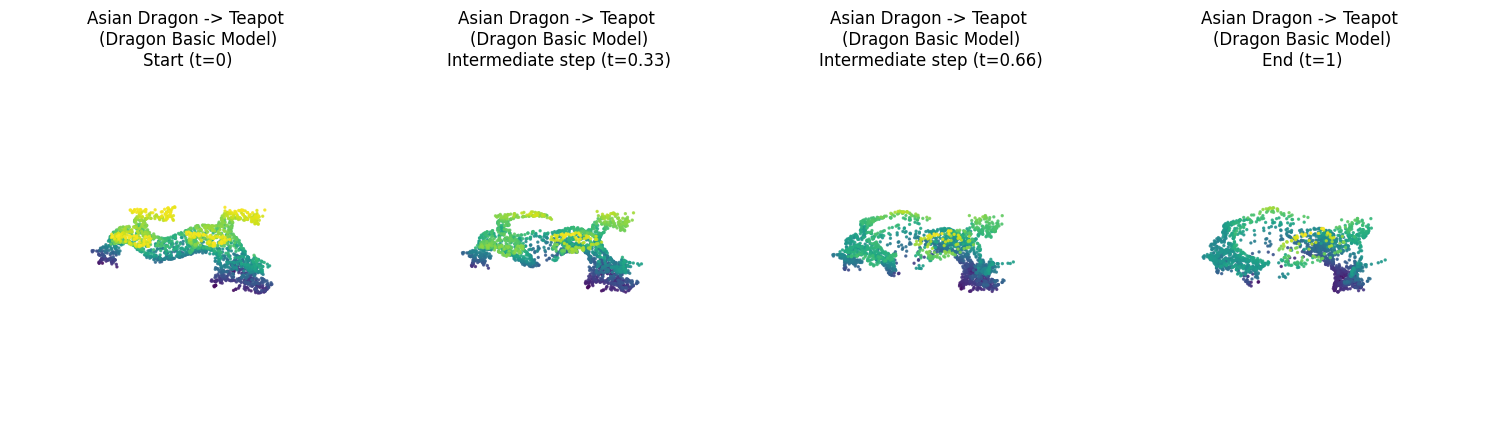

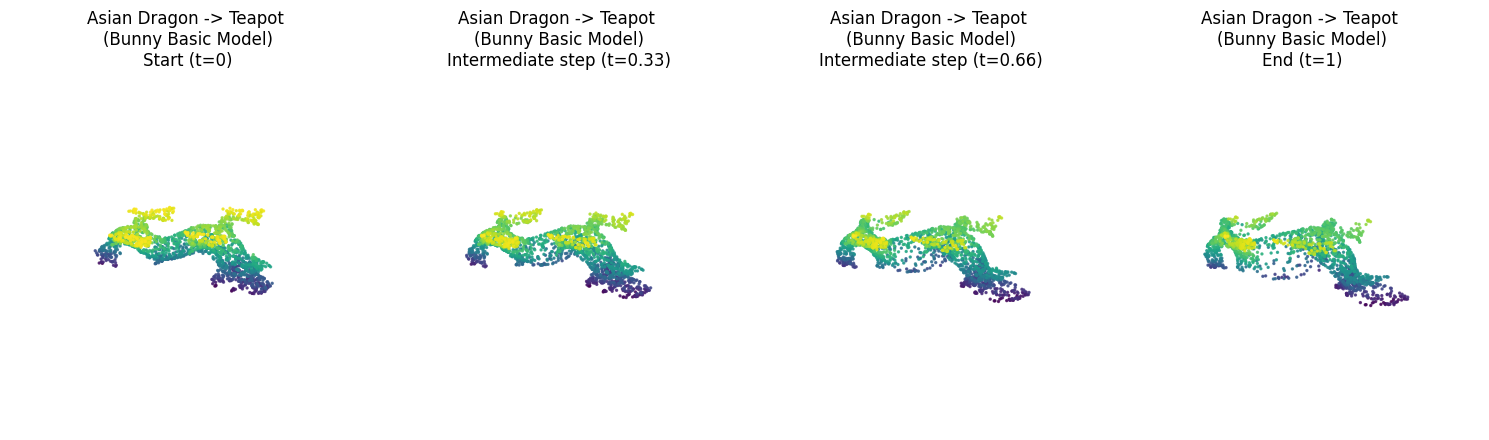

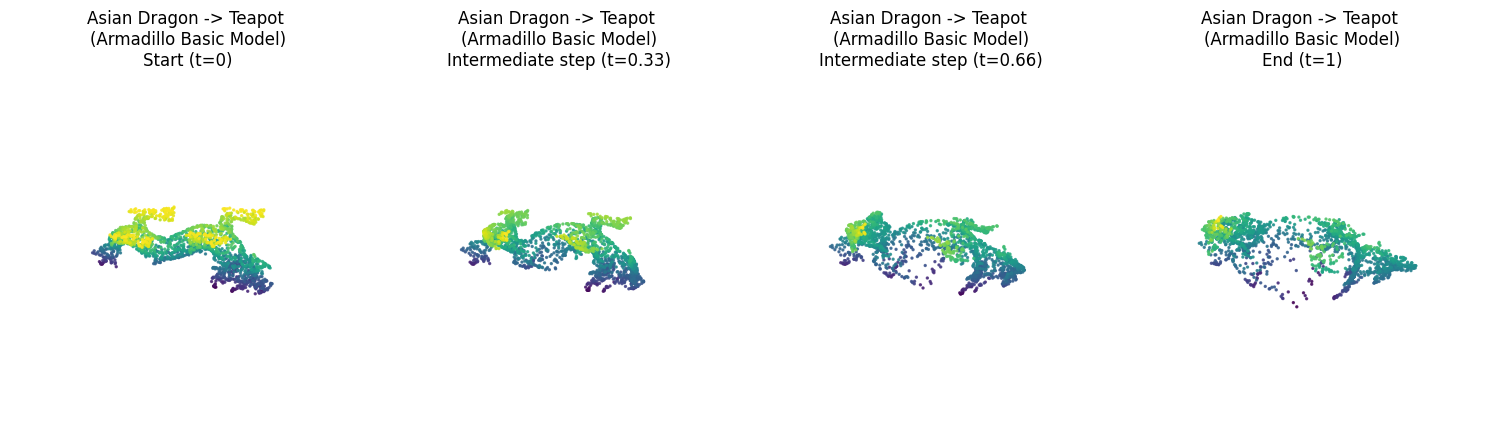

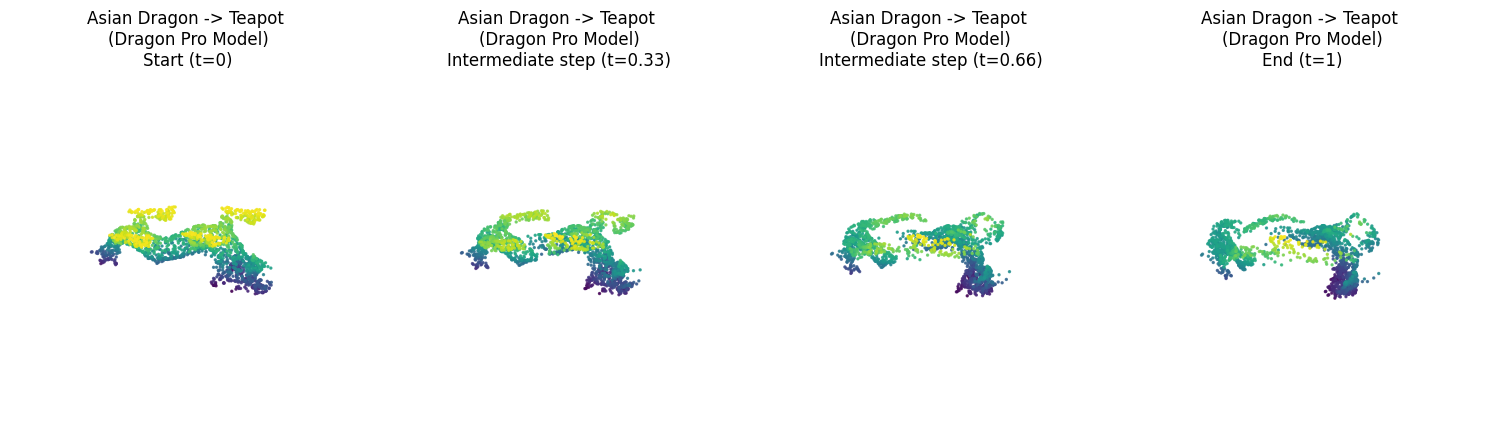

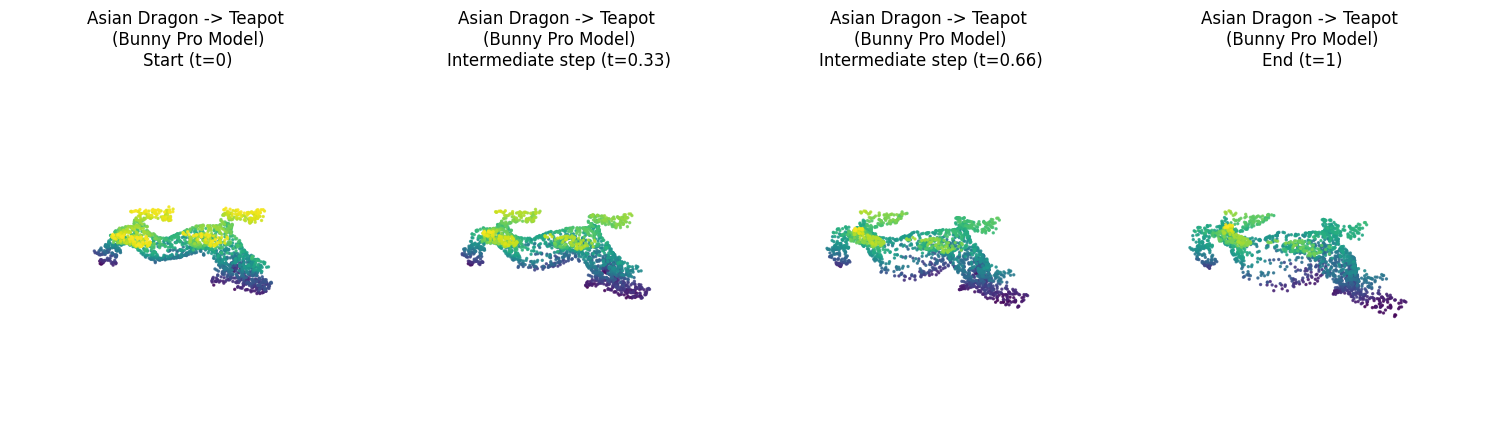

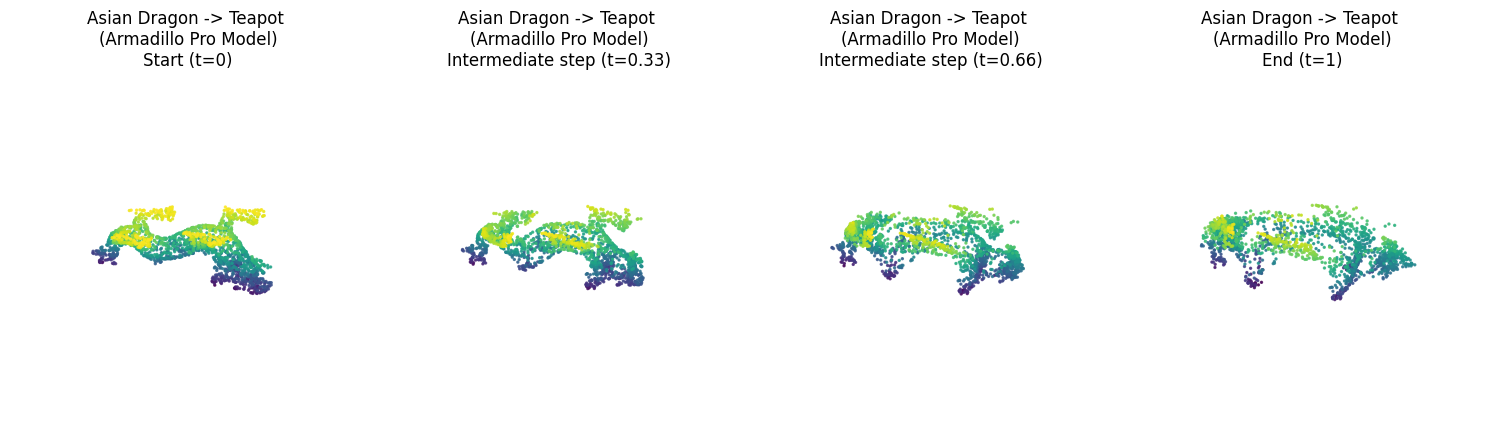

In [18]:
with torch.no_grad():
    visualize_morphing(model_dragon_basic, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Dragon Basic Model)")
    visualize_morphing(model_bunny_basic, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Bunny Basic Model)")
    visualize_morphing(model_armadillo_basic, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Armadillo Basic Model)")
    visualize_morphing(model_dragon, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Dragon Pro Model)")
    visualize_morphing(model_bunny, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Bunny Pro Model)")
    visualize_morphing(model_armadillo, dataset_asian_dragon, device, title="Asian Dragon -> Teapot \n(Armadillo Pro Model)")

# Metryki

In [19]:
def compute_metrics(transformed_pts, target_pts, threshold=0.05):
    chamfer = chamfer_distance(transformed_pts, target_pts)
    
    dists = torch.cdist(transformed_pts, target_pts)
    min_dist_to_target, _ = torch.min(dists, dim=2) 
    min_dist_to_source, _ = torch.min(dists, dim=1) 
    
    precision = (min_dist_to_target < threshold).float().mean().item()
    recall = (min_dist_to_source < threshold).float().mean().item()
    
    epsilon = 1e-8
    dice = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    iou = dice / (2 - dice + epsilon)
    
    return iou, dice, chamfer.item()


def evaluate_model(model, dataset, device, threshold=0.05):
    model.eval() 
    with torch.no_grad():
        sample = dataset[0]
        
        source_points = sample['source'].unsqueeze(0).to(device)
        target_points = sample['target'].unsqueeze(0).to(device)
        
        displacement = model(source_points)
        transformed_points = source_points + displacement
        
        iou, dice, chamfer = compute_metrics(transformed_points, target_points, threshold)
        
        return iou, dice, chamfer

threshold_val = 0.03

scenarios_1 = [[
    ("bunny basic flow", model_bunny_basic, dataset_bunny),
    ("dragon basic flow", model_dragon_basic, dataset_dragon),
    ("armadillo basic flow", model_armadillo_basic, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny_basic, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon_basic, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo_basic, dataset_asian_dragon)
], "Basic"]

scenarios_2 = [[
    ("bunny flow", model_bunny, dataset_bunny),
    ("dragon flow", model_dragon, dataset_dragon),
    ("armadillo flow", model_armadillo, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo, dataset_asian_dragon)
], "Pro"]

for scenarios in [scenarios_1, scenarios_2]:
    results = []
    scenario_name = scenarios[1]
    for name, model, dataset in scenarios[0]:
        iou, dice, cd = evaluate_model(model, dataset, device, threshold=threshold_val)
        results.append({
            "Method": name,
            "IoU": round(iou, 4),
            "Dice": round(dice, 4),
            "Chamfer": round(cd, 6) 
        })

    df_results = pd.DataFrame(results)
    df_results.set_index("Method", inplace=True)

    print(f"\n--- {scenario_name} Results Table ---")
    display(df_results)


--- Basic Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny basic flow,0.5802,0.7343,0.001347
dragon basic flow,0.5766,0.7314,0.001415
armadillo basic flow,0.5766,0.7314,0.001359
bunny flow asian dragon,0.0853,0.1572,0.049551
dragon flow asian dragon,0.1540,0.2669,0.025798
armadillo flow asian dragon,0.1445,0.2526,0.026562



--- Pro Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny flow,0.5845,0.7377,0.001340
dragon flow,0.6012,0.7510,0.001320
armadillo flow,0.5968,0.7475,0.001321
bunny flow asian dragon,0.0708,0.1322,0.049152
dragon flow asian dragon,0.1359,0.2392,0.036957
armadillo flow asian dragon,0.1372,0.2414,0.027571


In [20]:
def voxelize(points, resolution=32):
    voxel_grid = np.zeros((resolution, resolution, resolution), dtype=bool)

    norm_points = (points + 1.0) * 0.5 * (resolution - 1)
    norm_points = norm_points.astype(int)

    mask = (norm_points[:, 0] >= 0) & (norm_points[:, 0] < resolution) & \
           (norm_points[:, 1] >= 0) & (norm_points[:, 1] < resolution) & \
           (norm_points[:, 2] >= 0) & (norm_points[:, 2] < resolution)
    norm_points = norm_points[mask]

    voxel_grid[norm_points[:, 0], norm_points[:, 1], norm_points[:, 2]] = True
    return voxel_grid

def calculate_iou_dice(pred_points, target_points, res=32):
    if pred_points.dim() == 3:
        pred_points = pred_points.squeeze(0)
    if target_points.dim() == 3:
        target_points = target_points.squeeze(0)
    v_pred = voxelize(pred_points.detach().cpu().numpy(), res)
    v_target = voxelize(target_points.detach().cpu().numpy(), res)

    intersection = np.logical_and(v_pred, v_target).sum()
    union = np.logical_or(v_pred, v_target).sum()
    sum_volumes = v_pred.sum() + v_target.sum()

    iou = intersection / union if union > 0 else 0
    dice = (2 * intersection) / sum_volumes if sum_volumes > 0 else 0

    return iou, dice


def evaluate_model(model, dataset, device, resolution=32):
    model.eval() 
    with torch.no_grad(): 
        sample = dataset[0]
        
        source_points = sample['source'].unsqueeze(0).to(device)
        target_points = sample['target'].unsqueeze(0).to(device)
        
        displacement = model(source_points)
        transformed_points = source_points + displacement
        
        chamfer = chamfer_distance(transformed_points, target_points)
        chamfer_val = chamfer.item() if torch.is_tensor(chamfer) else chamfer
        
        iou, dice = calculate_iou_dice(transformed_points, target_points, res=resolution)
        
        return iou, dice, chamfer_val

grid_res = 32 

scenarios_1 = [[
    ("bunny basic flow", model_bunny_basic, dataset_bunny),
    ("dragon basic flow", model_dragon_basic, dataset_dragon),
    ("armadillo basic flow", model_armadillo_basic, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny_basic, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon_basic, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo_basic, dataset_asian_dragon)
], "Basic"]

scenarios_2 = [[
    ("bunny flow", model_bunny, dataset_bunny),
    ("dragon flow", model_dragon, dataset_dragon),
    ("armadillo flow", model_armadillo, dataset_armadillo),
    ("bunny flow asian dragon", model_bunny, dataset_asian_dragon),
    ("dragon flow asian dragon", model_dragon, dataset_asian_dragon),
    ("armadillo flow asian dragon", model_armadillo, dataset_asian_dragon)
], "Pro"]

for i, scenarios in enumerate([scenarios_1, scenarios_2]):
    results = []
    scenario_name = scenarios[1]
    
    for name, model, dataset in scenarios[0]:
        iou, dice, cd = evaluate_model(model, dataset, device, resolution=grid_res)
        results.append({
            "Method": name,
            "IoU": round(iou, 4),
            "Dice": round(dice, 4),
            "Chamfer": round(cd, 6) 
        })

    df_results = pd.DataFrame(results)
    df_results.set_index("Method", inplace=True)

    print(f"\n--- {scenario_name} Results Table ---")
    display(df_results)


--- Basic Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny basic flow,0.6602,0.7953,0.001282
dragon basic flow,0.6464,0.7853,0.001308
armadillo basic flow,0.6587,0.7942,0.001345
bunny flow asian dragon,0.0973,0.1773,0.051365
dragon flow asian dragon,0.1759,0.2992,0.025742
armadillo flow asian dragon,0.1801,0.3052,0.024717



--- Pro Results Table ---


,IoU,Dice,Chamfer
Method,,,
bunny flow,0.6467,0.7855,0.001316
dragon flow,0.6344,0.7763,0.001377
armadillo flow,0.6465,0.7853,0.001339
bunny flow asian dragon,0.0947,0.1730,0.047994
dragon flow asian dragon,0.1711,0.2922,0.035535
armadillo flow asian dragon,0.1697,0.2902,0.027763
